# Taller 4 — Inteligencia Artificial: Representación y Solución de Problemas

**Maestría en Matemáticas y Ciencias de la Computación** — Universidad del Rosario<br/>
**Profesor:** Nicolás Avilán Vargas, Ph.D.

Las ocho preguntas se resuelven sobre el modelo predador–presa del cuaderno
`Predador_Presa.ipynb` visto en clase, el cual se copia aquí sin cambios en sus reglas con el
objetivo de que el cuaderno sea autocontenido, y al que sólo se le agregan dos parámetros con
valor por defecto igual al original (`activacion` y `rebrote_inicial`) para poder correr las
variantes de las preguntas 5 y 7 sin duplicar las clases. Todas las corridas usan semilla fija,
de forma que cada cifra citada en el texto se reproduce al volver a ejecutar el cuaderno.

Cabe mencionar que la evolución de la grilla se muestra con un reproductor (play, pausa y
deslizador) en vez de instantáneas sueltas, pues al tratarse de un espacio que muta paso a paso
una foto cada cierto número de pasos pierde justo la información que interesa ver, mientras que
las curvas de población sí se dejan como gráficas estáticas porque el eje del tiempo ya cuenta
esa evolución.

In [1]:
import importlib.util

if importlib.util.find_spec("mesa") is None:  # p. ej. en Colab
    get_ipython().run_line_magic("pip", "install -q mesa")

from collections import Counter

from IPython.display import HTML
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import mesa
import numpy as np
import pandas as pd

plt.rcParams["animation.embed_limit"] = 40  # MB permitidos por reproductor embebido


def reproductor(fig, dibujar, n_cuadros, intervalo=120):
    """Reproductor HTML (play, pausa y deslizador) que funciona sin kernel."""
    anim = FuncAnimation(fig, dibujar, frames=n_cuadros, interval=intervalo, blit=False)
    html = anim.to_jshtml(default_mode="once")
    plt.close(fig)  # la figura vive dentro del reproductor, no como imagen suelta
    return HTML(html)


print("Versión de Mesa:", mesa.__version__)

Versión de Mesa: 3.5.1


## El modelo de la clase

Las clases `Animal`, `Presa` y `Predador` son las del cuaderno original, sin modificaciones.

In [2]:
class Animal(mesa.Agent):
    """Comportamiento común a presas y predadores."""

    def __init__(self, model, energia):
        super().__init__(model)
        self.energia = energia

    def mover(self):
        """Se mueve a una de las 8 celdas vecinas (vecindad de Moore), elegida al azar."""
        vecinos = self.model.grid.get_neighborhood(self.pos, moore=True, include_center=False)
        self.model.grid.move_agent(self, self.random.choice(vecinos))

    def morir(self, causa):
        """Quita al agente de la grilla y del modelo, y registra la causa."""
        self.model.muertes[(type(self).__name__, causa)] += 1
        self.model.registrar(f"{type(self).__name__} {self.unique_id} murió ({causa}) en {self.pos}")
        self.model.grid.remove_agent(self)
        self.remove()

    def reproducir(self, prob):
        """Con probabilidad prob, crea una cría en la misma celda y le da la mitad de su energía."""
        if self.random.random() < prob:
            self.energia /= 2
            cria = type(self)(self.model, self.energia)
            self.model.grid.place_agent(cria, self.pos)
            self.model.registrar(f"{type(self).__name__} {self.unique_id} tuvo una cría en {self.pos}")


class Presa(Animal):
    def step(self):
        self.mover()
        self.energia -= self.model.costo_presa

        # Comer: el pasto se consume y empieza a rebrotar
        x, y = self.pos
        if self.model.pasto[x, y]:
            self.model.pasto[x, y] = False
            self.model.contador[x, y] = self.model.tiempo_rebrote
            self.energia += self.model.ganancia_presa

        if self.energia <= 0:
            self.morir("hambre")
            return
        self.reproducir(self.model.prob_repro_presa)


class Predador(Animal):
    def step(self):
        self.mover()
        self.energia -= self.model.costo_predador

        # Cazar: si hay presas en la celda, se come una al azar
        presas = [a for a in self.model.grid.get_cell_list_contents([self.pos])
                  if isinstance(a, Presa)]
        if presas:
            victima = self.random.choice(presas)
            self.energia += self.model.ganancia_predador
            victima.morir("cazada")

        if self.energia <= 0:
            self.morir("hambre")
            return
        self.reproducir(self.model.prob_repro_predador)

En `ModeloPredadorPresa` se agregan los dos parámetros de las variantes:

- **`rebrote_inicial`:** Con `"aleatorio"` (original) cada celda vacía arranca con un contador
  entre 1 y `tiempo_rebrote`, mientras que con `"fijo"` todas arrancan en `tiempo_rebrote`
  (pregunta 5). El sorteo se hace igual en ambos casos y en el fijo simplemente se descarta, de
  forma que las dos variantes consumen la misma secuencia aleatoria y arrancan con los mismos
  animales en las mismas posiciones, es decir que la única diferencia entre ellas es el contador.
- **`activacion`:** Con `"shuffle_do"` (original) los agentes se activan en orden aleatorio en
  cada paso, mientras que con `"do"` se activan siempre en el mismo orden (pregunta 7).

In [3]:
class ModeloPredadorPresa(mesa.Model):
    def __init__(self, ancho=40, alto=40,
                 n_presas=260, n_predadores=45,
                 tiempo_rebrote=30,
                 ganancia_presa=6, ganancia_predador=30,
                 costo_presa=1, costo_predador=1,
                 prob_repro_presa=0.04, prob_repro_predador=0.05,
                 verbose=False, seed=None,
                 rebrote_inicial="aleatorio", activacion="shuffle_do"):
        super().__init__(rng=seed)
        # Parámetros (se guardan en el modelo para que los agentes los consulten)
        self.ancho, self.alto = ancho, alto
        self.tiempo_rebrote = tiempo_rebrote
        self.ganancia_presa, self.ganancia_predador = ganancia_presa, ganancia_predador
        self.costo_presa, self.costo_predador = costo_presa, costo_predador
        self.prob_repro_presa, self.prob_repro_predador = prob_repro_presa, prob_repro_predador
        self.verbose = verbose
        self.activacion = activacion
        self.muertes = Counter()

        self.grid = mesa.space.MultiGrid(ancho, alto, torus=True)

        # Pasto inicial: la mitad de las celdas, al azar; las demás con un rebrote pendiente
        self.pasto = np.array([[self.random.random() < 0.5 for _ in range(alto)] for _ in range(ancho)])
        self.contador = np.zeros((ancho, alto), dtype=int)
        for x in range(ancho):
            for y in range(alto):
                if not self.pasto[x, y]:
                    sorteo = self.random.randint(1, tiempo_rebrote)
                    # Pregunta 5: con "fijo" todas esperan el rebrote completo
                    self.contador[x, y] = sorteo if rebrote_inicial == "aleatorio" else tiempo_rebrote

        # Animales con energía inicial aleatoria, en posiciones aleatorias
        for _ in range(n_presas):
            self.grid.place_agent(Presa(self, self.random.randint(1, 2 * ganancia_presa)),
                                  (self.random.randrange(ancho), self.random.randrange(alto)))
        for _ in range(n_predadores):
            self.grid.place_agent(Predador(self, self.random.randint(1, 2 * ganancia_predador)),
                                  (self.random.randrange(ancho), self.random.randrange(alto)))

        self.datacollector = mesa.DataCollector(model_reporters={
            "Presas": lambda m: len(m.agents_by_type.get(Presa, [])),
            "Predadores": lambda m: len(m.agents_by_type.get(Predador, [])),
            "Pasto": lambda m: int(m.pasto.sum()),
        })
        self.datacollector.collect(self)   # estado inicial (paso 0)

    def registrar(self, mensaje):
        if self.verbose:
            print(mensaje)

    def crecer_pasto(self):
        """Las celdas sin pasto descuentan un paso; las que llegan a 0 vuelven a tener pasto."""
        sin_pasto = ~self.pasto
        self.contador[sin_pasto] -= 1
        self.pasto[sin_pasto & (self.contador <= 0)] = True

    def step(self):
        if self.activacion == "shuffle_do":
            self.agents.shuffle_do("step")   # cada animal actúa una vez, en orden aleatorio
        else:
            self.agents.do("step")           # pregunta 7: siempre en el mismo orden
        self.crecer_pasto()
        self.datacollector.collect(self)  # se registra DESPUÉS del paso
        if len(self.agents) == 0:
            self.running = False

## Herramientas de corrida y visualización

La función `simular` corre el modelo y guarda un cuadro cada `cada` pasos (el pasto y las
posiciones de los animales), de forma que el reproductor dibuja la historia ya calculada sin
volver a simular. Los colores son los del cuaderno original: Pasto en verde, tierra en café,
presas como puntos blancos y predadores como triángulos rojos.

In [4]:
PARAMS = dict(
    ancho=40, alto=40,
    n_presas=260, n_predadores=45,
    tiempo_rebrote=30,
    ganancia_presa=6, ganancia_predador=30,
    costo_presa=1, costo_predador=1,
    prob_repro_presa=0.04, prob_repro_predador=0.05,
)
CMAP_PASTO = ListedColormap(["#b08850", "#5fa84a"])   # 0 = tierra, 1 = pasto
LEYENDA = [
    Patch(color="#5fa84a", label="Pasto"),
    Patch(color="#b08850", label="Tierra"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
           markeredgecolor="black", markersize=6, label="Presa"),
    Line2D([0], [0], marker="^", color="none", markerfacecolor="red",
           markeredgecolor="black", markersize=7, label="Predador"),
]


def capturar(model):
    """Foto del estado espacial: pasto y posiciones de cada especie."""
    def posiciones(tipo):
        return np.array([a.pos for a in model.agents_by_type.get(tipo, [])]).reshape(-1, 2)
    return {"paso": model.steps, "pasto": model.pasto.copy(),
            "presas": posiciones(Presa), "predadores": posiciones(Predador)}


def simular(pasos=600, seed=None, cada=1, **cambios):
    """Corre el modelo base (con los cambios dados) y devuelve modelo, datos y cuadros."""
    model = ModeloPredadorPresa(**dict(PARAMS, **cambios), seed=seed)
    cuadros = [capturar(model)]
    for _ in range(pasos):
        if not model.running:
            break
        model.step()
        if model.steps % cada == 0:
            cuadros.append(capturar(model))
    return model, model.datacollector.get_model_vars_dataframe(), cuadros


def dibujar_cuadro(cuadro, ax, titulo=""):
    # pasto[x, y] -> transponemos para que x sea horizontal e y vertical
    ax.imshow(cuadro["pasto"].T, origin="lower", cmap=CMAP_PASTO, vmin=0, vmax=1)
    for clave, estilo in [("presas", dict(s=14, c="white")),
                          ("predadores", dict(s=30, c="red", marker="^"))]:
        if len(cuadro[clave]):
            ax.scatter(cuadro[clave][:, 0], cuadro[clave][:, 1],
                       edgecolors="black", linewidths=0.4, **estilo)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{titulo}Paso {cuadro['paso']} · presas {len(cuadro['presas'])}"
                 f" · predadores {len(cuadro['predadores'])}", fontsize=9)


def reproducir_grillas(series, titulos=("",), intervalo=120):
    """Una o varias historias lado a lado, movidas por el mismo deslizador."""
    fig, axes = plt.subplots(1, len(series), figsize=(4.6 * len(series), 4.5), dpi=64,
                             squeeze=False)
    axes = axes[0]

    def dibujar(i):
        for ax, cuadros, titulo in zip(axes, series, titulos):
            ax.clear()
            dibujar_cuadro(cuadros[min(i, len(cuadros) - 1)], ax, titulo)
        axes[0].legend(handles=LEYENDA, loc="upper left", fontsize=7, framealpha=0.85)

    fig.tight_layout()
    return reproductor(fig, dibujar, max(len(c) for c in series), intervalo)


def curvas(datos, ax, titulo):
    ax.plot(datos["Presas"], color="green", label="Presas")
    ax.plot(datos["Predadores"], color="red", label="Predadores")
    ax.plot(datos["Pasto"] / 4, color="goldenrod", alpha=0.7, label="Celdas con pasto / 4")
    ax.set_title(titulo); ax.grid(alpha=0.3)

## Corrida base

La corrida de referencia es la de la clase (semilla 1, 600 pasos). El reproductor guarda un
cuadro cada 3 pasos.

In [5]:
model, datos, cuadros_base = simular(seed=1, cada=3)
reproducir_grillas([cuadros_base])

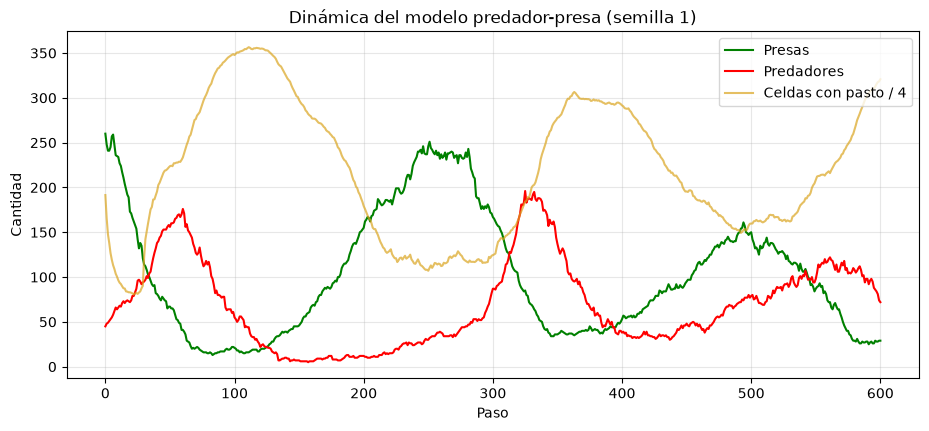

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
curvas(datos, ax, "Dinámica del modelo predador-presa (semilla 1)")
ax.set_xlabel("Paso"); ax.set_ylabel("Cantidad"); ax.legend(loc="upper right")
plt.show()

## Pregunta 1 — `agents_by_type`

> ¿Qué información da `self.agents_by_type[Presa]`?

**¿Qué información da?** El conjunto de todas las presas que siguen vivas en el modelo en ese
instante, pues `agents_by_type` es un diccionario (propio de `mesa.Model`) que agrupa a los
agentes por su clase, de forma que al usar el accesor `[]` con la llave `Presa` se obtiene el
listado de objetos cuyo tipo de dato es el de la presa. Cabe mencionar dos detalles: El accesor
`[]` no se aplica sobre el modelo completo sino sobre su atributo `agents_by_type`, y lo que
devuelve no es una lista simple sino un `AgentSet`, el cual admite `len` (de ahí que el
reportero `"Presas"` del `DataCollector` lo use para contar la población en cada paso), así como
`do`, `shuffle_do`, `select` o `get` para operar sobre todas las presas a la vez. El reportero
lo consulta con `.get(Presa, [])` en lugar de `[Presa]` para que no falle si la llave no existe.

In [7]:
presas = model.agents_by_type[Presa]
print("agents_by_type:", type(model.agents_by_type).__name__,
      "con llaves", [t.__name__ for t in model.agents_by_type])
print("agents_by_type[Presa]:", type(presas).__name__, "con", len(presas), "presas",
      f"(DataCollector en el paso {model.steps}: {datos['Presas'].iloc[-1]})")
print(f"Energía media de las presas vivas: {np.mean(presas.get('energia')):.2f}")

agents_by_type: dict con llaves ['Presa', 'Predador']
agents_by_type[Presa]: _HardKeyAgentSet con 29 presas (DataCollector en el paso 600: 29)
Energía media de las presas vivas: 31.48


## Pregunta 2 — El `return` tras morir

> ¿Qué función cumple la instrucción `return` en las clases **Presa** y **Predador**? ¿Qué
> pasaría si no se incluye?

**¿Qué función cumple?** Corta el método `step` en el momento en que el animal muere, de forma
que deja de accionar y transformar su entorno por el hecho de estar vivo. En Python la palabra
clave `return` termina la ejecución de una función o método (en este caso sin devolver ningún
valor, es decir que devuelve `None`), y aquí se usa como una salida temprana: Si al evaluarse
dentro del intervalo discreto de tiempo (step) el animal queda con déficit de energía
(`energia <= 0`), se llama a `morir`, que lo retira de la grilla y del modelo, y el `return` evita
que se ejecute la línea siguiente, que es `reproducir`.

**¿Qué pasaría sin él?** El animal ya muerto seguiría de largo hasta `reproducir`, y como
`remove_agent` le deja la posición en `None`, cada vez que el sorteo de reproducción saliera
favorable intentaría ubicar una cría en `self.pos = None`, lo cual interrumpe la simulación con
un `TypeError`. Con `prob_repro_presa = 0.04` esto ocurre en cerca del 4 % de las muertes por
hambre, y como la corrida base tiene más de mil, es prácticamente seguro que la simulación se
caiga, pero aún si no se cayera el modelo sería incorrecto, pues un cadáver tendría crías y les
cedería energía. Abajo se fuerza el caso con una presa sin `return` y probabilidad de
reproducción 1.

In [8]:
class PresaSinReturn(Presa):
    """Idéntica a Presa, pero sin el return tras morir."""

    def step(self):
        self.mover()
        self.energia -= self.model.costo_presa
        x, y = self.pos
        if self.model.pasto[x, y]:
            self.model.pasto[x, y] = False
            self.model.contador[x, y] = self.model.tiempo_rebrote
            self.energia += self.model.ganancia_presa
        if self.energia <= 0:
            self.morir("hambre")
        self.reproducir(self.model.prob_repro_presa)


prueba = ModeloPredadorPresa(ancho=5, alto=5, n_presas=0, n_predadores=0,
                             prob_repro_presa=1.0, seed=1)
prueba.pasto[:] = False                    # sin pasto: no recupera energía
presa = PresaSinReturn(prueba, energia=1)  # muere en este mismo paso
prueba.grid.place_agent(presa, (2, 2))
try:
    presa.step()
except TypeError as error:
    print(f"TypeError: {error}  (pos de la presa muerta: {presa.pos})")

TypeError: cannot unpack non-iterable NoneType object  (pos de la presa muerta: None)


## Pregunta 3 — Los mensajes de `registrar`

> ¿Por qué no se muestran los mensajes que se generan? Pruebe con este modelo:
>
> ```python
> m = ModeloPredadorPresa(
>    ancho=10, alto=10, n_presas=20, n_predadores=5, verbose=True, seed=1
> )
> for _ in range(3):
>    m.step()
> ```

**¿Por qué no se muestran?** Porque en la corrida base el modelo se crea con `verbose=False`,
que es el valor por defecto del constructor, y todos los mensajes (muertes y crías) pasan por el
método `registrar`, el cual sólo hace `print` cuando `self.verbose` es verdadero. Es decir que
los mensajes sí se generan en cada `morir` y `reproducir`, pero se descartan en silencio, lo
cual tiene sentido en la corrida de 600 pasos, que tiene miles de muertes y nacimientos y
llenaría la salida de la celda.

El ciclo `for` del enunciado no imprime nada por sí mismo (ni siquiera usa la variable
iteradora), y lo que cambia frente a la corrida base es el `verbose=True` al definir el modelo,
con el cual se empiezan a imprimir los eventos de cada paso indicando qué ocurre en el
desarrollo del modelo, como se ve al ejecutarlo:

In [9]:
m = ModeloPredadorPresa(
   ancho=10, alto=10, n_presas=20, n_predadores=5, verbose=True, seed=1
)
for _ in range(3):
   m.step()

Presa 12 murió (hambre) en (4, 0)
Presa 19 murió (cazada) en (9, 5)
Presa 9 murió (cazada) en (2, 5)
Presa 2 tuvo una cría en (5, 2)
Presa 26 murió (cazada) en (5, 2)
Presa 10 murió (hambre) en (3, 6)
Presa 2 murió (hambre) en (6, 3)


Se trata de un mundo pequeño (100 celdas) a propósito, de forma que en tres pasos hay pocos
eventos y se pueden leer uno a uno: Presas que mueren de hambre o cazadas y presas que tienen
crías, donde el número es el `unique_id` del animal y la tupla su celda.

## Pregunta 4 — `self.muertes` y el `Counter`

> ¿Qué tipo de estructura es `self.muertes`? ¿Por qué se usa un `Counter` y no un diccionario
> común (`{}`)? Después de la corrida base, imprima `model.muertes`: ¿qué limita más a las
> presas, los predadores o el alimento?

**¿Qué tipo de estructura es?** Un `collections.Counter`, que es una subclase de `dict`
especializada en contar, donde cada llave es la tupla `(especie, causa)` y su valor el número de
individuos muertos por esa causa. Al ser un diccionario conserva la complejidad computacional de
acceso O(1) desde que se conozca la llave, con el pequeño detalle de que una llave que no existe
vale 0 en vez de lanzar error.

**¿Por qué no un `{}`?** Por esa última propiedad, pues `morir` hace
`self.model.muertes[(especie, causa)] += 1` y la primera vez que aparece una combinación la llave
aún no existe, así que con un diccionario común esa línea lanza `KeyError` y habría que escribir
`d[k] = d.get(k, 0) + 1` o inicializar todas las combinaciones de antemano, mientras que el
`Counter` lleva el registro auto-incremental sin preparación previa (y de paso trae
`most_common` para ordenar descendientemente).

In [10]:
print("¿Es un dict?", isinstance(model.muertes, dict))
print("Llave inexistente en el Counter:", model.muertes[("Presa", "vejez")])
try:
    comun = {}
    comun[("Presa", "hambre")] += 1
except KeyError as error:
    print("Con {} común: KeyError", error)

print("\nMuertes acumuladas (semilla 1):")
for (especie, causa), n in model.muertes.most_common():
    print(f"  {especie:9s} por {causa:7s}: {n}")

¿Es un dict? True
Llave inexistente en el Counter: 0
Con {} común: KeyError ('Presa', 'hambre')

Muertes acumuladas (semilla 1):
  Predador  por hambre : 1996
  Presa     por cazada : 1344
  Presa     por hambre : 1268


Como el enunciado de la clase sugiere repetir con varias semillas, se corren 5 y se compara qué
fracción de las muertes de presas corresponde a caza:

In [11]:
filas = []
for s in range(5):
    m_s, _, _ = simular(seed=s, cada=10**6)
    filas.append({"semilla": s,
                  "cazadas": m_s.muertes[("Presa", "cazada")],
                  "hambre": m_s.muertes[("Presa", "hambre")]})
causas = pd.DataFrame(filas).set_index("semilla")
causas["% cazadas"] = (100 * causas["cazadas"] / causas.sum(axis=1)).round(1)
causas

,cazadas,hambre,% cazadas
semilla,,,
0,1412,1048,57.4
1,1344,1268,51.5
2,1414,797,64.0
3,1335,1058,55.8
4,1364,985,58.1


**¿Qué limita más a las presas?** Los predadores, pues en la corrida base las presas cazadas son
1.344 frente a 1.268 muertas de hambre, y en las 5 semillas la caza es la causa mayoritaria (entre
el 51 % y el 64 % de las muertes de presas). No obstante, la diferencia es pequeña y quisiera
hacer una anotación, pues al analizar la gráfica de la corrida base se aprecia como la relación
entre las *celdas con pasto* y las *presas* es inversa (cuando una está en máximos locales la otra
está en mínimos locales), por lo que no atribuiría la muerte de las presas totalmente a la caza
sino también a una restricción del entorno: Al haber muchos individuos se agota el pasto, lo cual
frena el crecimiento de su población, y en esos mismos momentos los predadores tienen un volumen
de presas mucho mayor, lo que aumenta la caza y, al caer las presas, da tiempo al pasto para
regenerarse. Es decir que las dos causas no son independientes, sino que el alimento pone el techo
y los predadores recortan la población antes de llegar a él.

## Pregunta 5 — Rebrote inicial fijo

> Al inicializar el pasto, las celdas vacías reciben un contador aleatorio:
>
> ```python
> self.contador[x, y] = self.random.randint(1, tiempo_rebrote)
> ```
>
> ¿Qué pasaría si todas recibieran exactamente `tiempo_rebrote`? Haga el cambio, ejecute el
> modelo y compare la curva del pasto con la original.

El cambio corresponde a `rebrote_inicial="fijo"`, y se compara contra la original con la misma
semilla (y, como se explicó arriba, con los mismos animales en las mismas posiciones).

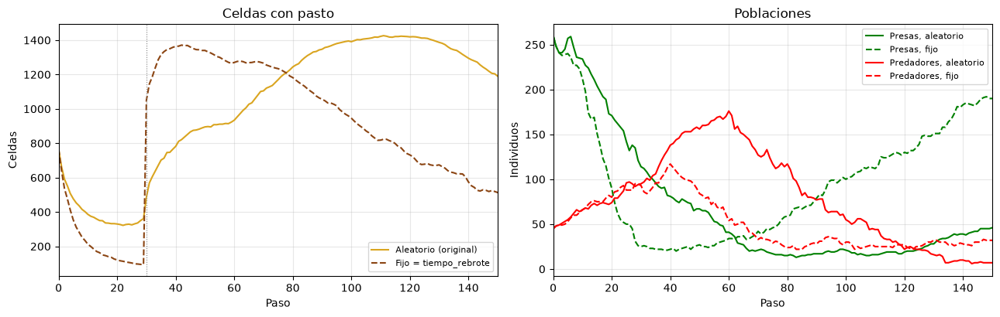

,aleatorio,fijo
pasto mínimo (pasos 0-29),322,94
pasto en el paso 30,487,1051
paso del máximo de pasto (0-150),111,42
presas en el paso 30,114,25
pico de predadores (0-150),176,117
mayor salto de pasto en un paso (desde el 60),36,30


In [12]:
model_fijo, datos_fijo, cuadros_fijo = simular(seed=1, rebrote_inicial="fijo")
_, datos_ale, cuadros_ale = simular(seed=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(datos_ale["Pasto"], color="goldenrod", label="Aleatorio (original)")
axes[0].plot(datos_fijo["Pasto"], color="saddlebrown", ls="--", label="Fijo = tiempo_rebrote")
axes[0].axvline(30, color="gray", lw=0.8, ls=":")
axes[0].set(title="Celdas con pasto", xlabel="Paso", ylabel="Celdas")
axes[1].plot(datos_ale["Presas"], color="green", label="Presas, aleatorio")
axes[1].plot(datos_fijo["Presas"], color="green", ls="--", label="Presas, fijo")
axes[1].plot(datos_ale["Predadores"], color="red", label="Predadores, aleatorio")
axes[1].plot(datos_fijo["Predadores"], color="red", ls="--", label="Predadores, fijo")
axes[1].set(title="Poblaciones", xlabel="Paso", ylabel="Individuos")
for ax in axes:
    ax.set_xlim(0, 150); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

resumen = pd.DataFrame({
    nombre: {"pasto mínimo (pasos 0-29)": d["Pasto"].iloc[:30].min(),
             "pasto en el paso 30": d["Pasto"].iloc[30],
             "paso del máximo de pasto (0-150)": d["Pasto"].iloc[:150].idxmax(),
             "presas en el paso 30": d["Presas"].iloc[30],
             "pico de predadores (0-150)": d["Predadores"].iloc[:150].max(),
             "mayor salto de pasto en un paso (desde el 60)":
                 int(d["Pasto"].diff().abs().iloc[60:].max())}
    for nombre, d in [("aleatorio", datos_ale), ("fijo", datos_fijo)]})
resumen

En el reproductor se ven las dos historias lado a lado con el mismo deslizador (un cuadro por
paso durante los primeros 100 pasos), de forma que el reverdecimiento simultáneo del paso 30 se
aprecia sobre la grilla completa:

In [13]:
reproducir_grillas([cuadros_ale[:101], cuadros_fijo[:101]], ("Aleatorio · ", "Fijo · "),
                   intervalo=150)

In [14]:
filas = []
for s in range(5):
    for variante in ["aleatorio", "fijo"]:
        m_s, _, _ = simular(seed=s, cada=10**6, rebrote_inicial=variante)
        filas.append({"semilla": s, "rebrote inicial": variante,
                      "presas por hambre": m_s.muertes[("Presa", "hambre")],
                      "presas cazadas": m_s.muertes[("Presa", "cazada")]})
muertes_rebrote = pd.DataFrame(filas).pivot(index="semilla", columns="rebrote inicial")
for variante in ["aleatorio", "fijo"]:
    hambre = muertes_rebrote[("presas por hambre", variante)]
    cazadas = muertes_rebrote[("presas cazadas", variante)]
    muertes_rebrote[("% hambre", variante)] = (100 * hambre / (hambre + cazadas)).round(1)
muertes_rebrote

presas por hambre       presas cazadas        % hambre      
rebrote inicial         aleatorio  fijo      aleatorio  fijo aleatorio  fijo
semilla                                                                     
0                            1048  1475           1412  1159      42.6  56.0
1                            1268  1240           1344  1222      48.5  50.4
2                             797  1147           1414  1104      36.0  51.0
3                            1058  1957           1335  1092      44.2  64.2
4                             985  1325           1364  1178      41.9  52.9

**¿Qué pasaría?** El rebrote de todas las celdas vacías se sincroniza, pues lo que dice
`self.random.randint(1, tiempo_rebrote)` es que el tiempo que le falta a cada celda para volver a
tener pasto es un valor entre 1 y 30 (en la definición del modelo), de modo que en la versión
original cada paso rebrota una fracción de ellas y la curva del pasto baja suavemente hasta un
mínimo de 322 celdas para luego recuperarse de forma gradual. Al remover la posibilidad de que
tome menos tiempo que el máximo, ninguna celda vacía rebrota durante los primeros 29 pasos (las
que se comen en ese tiempo también reciben 30), así que la curva del pasto cae sin pausa hasta 94
celdas y en el paso 30 salta de golpe a 1.051, cuando todas las celdas que arrancaron vacías
rebrotan en el mismo instante (el escalón vertical de la curva y el reverdecimiento simultáneo de
la grilla en el reproductor).

Ese periodo de escasez causa lógicamente que las presas mueran de hambre, pues llegan al paso 30
con 25 individuos frente a 114 en la original, y con ello se adelanta el ciclo completo: Con pocas
presas los predadores alcanzan un pico de 117 en vez de 176, el pasto, sin quien lo coma, llega a
su máximo en el paso 42 en vez del 111, y las presas se recuperan mucho antes que en la original.
Después del pulso las celdas se comen en pasos distintos y el rebrote se vuelve a desincronizar,
de forma que a partir del paso 60 el mayor salto del pasto en un solo paso es de 30 celdas (36 en
la original), es decir que el pulso no se repite y su efecto queda en el desfase del ciclo.

Respecto a las muertes, la tabla de 5 semillas muestra que la proporción de presas muertas por
hambre sube en todas ellas (entre 1.9 y 20 puntos porcentuales) y que las cazadas bajan en todas,
lo cual confirma que el rebrote fijo inclina la balanza hacia el hambre, y que el sorteo aleatorio
del contador sirve precisamente para no arrancar el modelo con un mundo artificialmente
sincronizado.

> **Nota.** Las cifras de 1.706 muertes por hambre y 1.132 por caza que se obtienen al reemplazar
> la línea directamente corresponden a otra historia aleatoria, pues al dejar de llamar a
> `randint` el generador queda desfasado y los animales nacen en otras posiciones y con otra
> energía, por lo que en este cuaderno se conserva el sorteo y sólo se descarta su valor, de forma
> que la comparación aísla el efecto del contador. Con esa comparación pareada el efecto en la
> semilla 1 resulta mucho menor (1.240 por hambre y 1.222 por caza frente a 1.268 y 1.344), lo
> cual sugiere que buena parte de la diferencia de aquella corrida era variabilidad de la semilla y
> no del contador, y es la razón por la cual la conclusión se apoya en las 5 semillas.

## Pregunta 6 — Energía en la reproducción

> En el método `reproducir`, ¿cuánta energía tienen en total el progenitor y la cría antes y
> después del nacimiento? ¿Por qué es importante que la reproducción no cree energía?

**¿Cuánta energía hay antes y después?** La misma, pues si el progenitor tiene una energía $E$
antes de reproducirse (y la cría aún no existe), la línea `self.energia /= 2` le deja $E/2$ y la
cría se crea con ese mismo valor, de modo que después del nacimiento el total es
$E/2 + E/2 = E$. Es decir que la reproducción sólo reparte la energía existente entre dos
individuos y no agrega nada.

In [15]:
prueba = ModeloPredadorPresa(ancho=5, alto=5, n_presas=0, n_predadores=0, seed=1)
madre = Presa(prueba, energia=10)
prueba.grid.place_agent(madre, (2, 2))
antes = madre.energia

madre.reproducir(prob=1.0)  # se fuerza el nacimiento
cria = next(a for a in prueba.agents if a is not madre)
print(f"Antes:   progenitor {antes:.1f}")
print(f"Después: progenitor {madre.energia:.1f} + cría {cria.energia:.1f}"
      f" = {madre.energia + cria.energia:.1f}")

Antes:   progenitor 10.0
Después: progenitor 5.0 + cría 5.0 = 10.0


**¿Por qué es importante?** Porque la energía sólo debe entrar al sistema por el alimento (el
pasto para las presas y las presas para los predadores) y salir por el costo de cada paso. Basado
en la física no hay un modelo coherente donde un proceso genere más materia o energía de la que
consume, y aunque en lo computacional se puede plantear y estudiar, para esta simulación que busca
emular procesos naturales es importante que no se cree energía, pues de lo contrario cada
reproducción sería una fuente gratuita de energía y la población podría crecer sólo con
reproducirse, sin depender del alimento, de forma que el pasto dejaría de poner un techo a las
presas, el acoplamiento con los predadores se rompería y eventualmente no existiría espacio para
albergar individuos que sólo pueden morir por causas no naturales. Además, el reparto a la mitad
tiene un costo real: Si el progenitor tiene poca energía, tanto él como la cría quedan cerca de
morir de hambre, lo cual frena la reproducción cuando escasea el alimento.

## Pregunta 7 — Orden de activación

> Reemplace `self.agents.shuffle_do("step")` por `self.agents.do("step")`, que activa a los
> agentes siempre en el mismo orden. Compare las curvas de población con tres semillas.
> ¿Aparecen patrones artificiales? ¿Por qué es importante activar a los agentes en orden
> aleatorio?

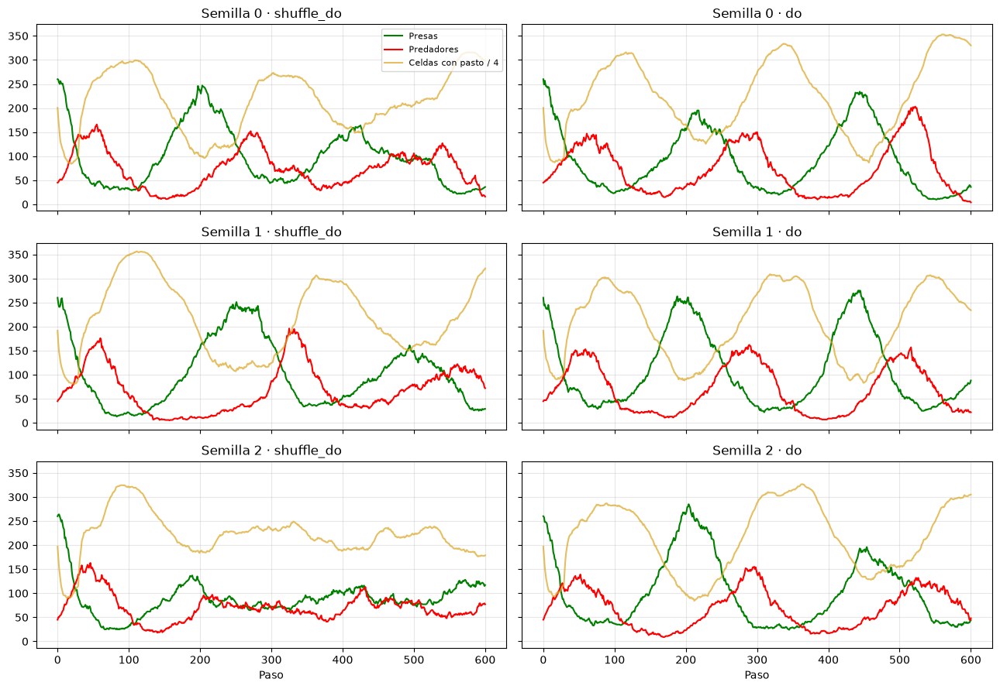

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True, sharey=True)
for fila, s in zip(axes, [0, 1, 2]):
    for ax, activacion in zip(fila, ["shuffle_do", "do"]):
        _, d, _ = simular(seed=s, cada=10**6, activacion=activacion)
        curvas(d, ax, f"Semilla {s} · {activacion}")
axes[0, 0].legend(fontsize=8, loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("Paso")
plt.tight_layout(); plt.show()

Como tres semillas son pocas para distinguir un efecto de la variabilidad propia del modelo, se
resumen además 20 semillas por variante con las métricas del `barrido` de la clase (coexistencia
al final y poblaciones promedio en la segunda mitad), la amplitud de las presas (su desviación
estándar en la segunda mitad) y una medida de regularidad del ciclo (el pico de la
autocorrelación de la serie de presas entre los rezagos 100 y 350, que vale 1 para un ciclo
perfecto y se acerca a 0 cuando no hay periodicidad), junto con la desviación estándar entre
semillas de cada métrica:

In [17]:
def regularidad(serie, rezagos=range(100, 350)):
    """Pico de autocorrelación de la serie desde el paso 100 (1 = ciclo perfecto)."""
    x = serie.iloc[100:].to_numpy(dtype=float)
    x = x - x.mean()
    if not x.any():
        return np.nan
    r = np.correlate(x, x, "full")[len(x) - 1:] / (x @ x)
    return r[list(rezagos)].max()


filas = []
for activacion in ["shuffle_do", "do"]:
    for s in range(20):
        m_s, d, _ = simular(seed=s, cada=10**6, activacion=activacion)
        segunda_mitad = d.iloc[len(d) // 2:]
        filas.append({"activacion": activacion,
                      "coexisten": d["Presas"].iloc[-1] > 0 and d["Predadores"].iloc[-1] > 0,
                      "presas_prom": segunda_mitad["Presas"].mean(),
                      "predadores_prom": segunda_mitad["Predadores"].mean(),
                      "amplitud_presas": segunda_mitad["Presas"].std(),
                      "regularidad": regularidad(d["Presas"]),
                      "% cazadas": 100 * m_s.muertes[("Presa", "cazada")]
                                   / max(1, m_s.muertes[("Presa", "cazada")]
                                         + m_s.muertes[("Presa", "hambre")])})
orden = pd.DataFrame(filas)
orden.groupby("activacion").agg(["mean", "std"]).round(2)

coexisten       presas_prom        predadores_prom        \
                mean   std        mean    std            mean   std   
activacion                                                            
do              0.95  0.22      104.92  39.53           64.53  16.4   
shuffle_do      0.90  0.31      109.79  53.76           60.33  22.4   

           amplitud_presas        regularidad       % cazadas         
                      mean    std        mean   std      mean    std  
activacion                                                            
do                   57.68  21.19        0.41  0.12     50.31  11.65  
shuffle_do           54.33  23.34        0.37  0.18     47.85  15.16

Para entender el resultado sirve ver *qué* orden impone `do`: Es el orden en que los agentes se
registraron en el modelo, de modo que en el paso 0 son las 260 presas seguidas de los 45
predadores, pero cada cría se agrega al final de la lista y cada muerto sale de ella. La celda
siguiente cuenta, con `do`, cuántas rachas de una misma especie hay en el orden de activación y
cuántos de los animales iniciales siguen vivos:

In [18]:
m_do = ModeloPredadorPresa(**PARAMS, seed=1, activacion="do")
n_iniciales = len(m_do.agents)
for paso in range(301):
    if paso in (0, 10, 25, 50, 100, 300):
        tipos = [type(a).__name__ for a in m_do.agents]
        rachas = 1 + sum(a != b for a, b in zip(tipos, tipos[1:]))
        vivos = sum(a.unique_id <= n_iniciales for a in m_do.agents)
        print(f"Paso {paso:3d}: {len(tipos):3d} agentes en {rachas:2d} rachas de especie"
              f" | iniciales vivos: {vivos}")
    m_do.step()

Paso   0: 305 agentes en  2 rachas de especie | iniciales vivos: 305
Paso  10: 286 agentes en 27 rachas de especie | iniciales vivos: 200
Paso  25: 208 agentes en 50 rachas de especie | iniciales vivos: 95
Paso  50: 206 agentes en 72 rachas de especie | iniciales vivos: 49
Paso 100:  97 agentes en 42 rachas de especie | iniciales vivos: 7
Paso 300: 174 agentes en 58 rachas de especie | iniciales vivos: 0


In [19]:
_, _, cuadros_shuffle = simular(seed=1, cada=5)
_, _, cuadros_do = simular(seed=1, cada=5, activacion="do")
reproducir_grillas([cuadros_shuffle, cuadros_do], ("shuffle_do · ", "do · "))

**¿Aparecen patrones artificiales?** No se encontraron a nivel de las curvas de población, pues al
cambiar `shuffle_do` por `do` siguen apareciendo las mismas oscilaciones desfasadas de presas,
predadores y pasto, con un periodo parecido entre picos de presas. Cabe
mencionar que en estas tres semillas los ciclos con `do` se ven algo más regulares que con
`shuffle_do` (en la semilla 2 con orden aleatorio las oscilaciones incluso se amortiguan después
del paso 200), lo cual podría tomarse como un patrón del orden fijo, pero el resumen de 20
semillas no lo sostiene: La regularidad media es apenas mayor con `do` (0.41 frente a 0.37, con
desviaciones entre semillas de 0.12 y 0.18), al igual que la amplitud (57.7 con `do` frente a 54.3 con `shuffle_do`), las presas promedio (104.9 frente a 109.8)
y los predadores promedio (64.5 frente a 60.3), con diferencias muy por debajo de la desviación
estándar entre semillas de una misma variante (entre 16 y 54 individuos), e incluso la coexistencia
es prácticamente igual (19 de 20 corridas con `do` y 18 de 20 con `shuffle_do`). Es decir que lo
que se ve en tres semillas está dentro de la variabilidad propia del modelo.

La razón está en la tabla de rachas: El orden por especie (todas las presas antes que todos los
predadores) sólo existe en el paso 0, y como en 25 pasos ya murieron 210 de los 305 animales
iniciales y las crías entran al final de la lista, el orden fijo pasa a ser un orden por
antigüedad donde las dos especies quedan intercaladas, de forma que en un tiempo lo
suficientemente significativo las gráficas con orden fijo no se distinguen de las de orden
aleatorio.

> **Nota.** Que no aparezcan en las curvas no quiere decir que el orden fijo sea inocuo, pues
> sigue habiendo un sesgo sistemático a nivel individual: Con `do` los animales más viejos actúan
> siempre primero, de forma que llegan antes al pasto que comparten con presas más jóvenes y los
> predadores más viejos cazan antes que los recién nacidos. En este modelo ese sesgo no alcanza a
> notarse porque la única interacción es un encuentro al azar en la misma celda, pero en uno con
> competencia más fuerte (o si se activa por tipo, primero todas las presas y luego todos los
> predadores) sí podría producir ventajas artificiales.

**¿Por qué es importante el orden aleatorio?** Porque en el modelo todos los agentes deberían
actuar "al mismo tiempo" dentro de un paso, y como la computadora tiene que ejecutarlos uno tras
otro, cualquier orden fijo le da a unos agentes ventaja sobre otros por una razón que no existe en
el fenómeno que se modela (su posición en una lista). Al barajar el orden en cada paso esa ventaja
se reparte al azar entre todos, de modo que en promedio nadie queda favorecido y lo que se
observa es efecto de las reglas y no del programador de turnos.

## Pregunta 8 — `crecer_pasto` línea por línea

> Explique, línea por línea, qué hace el método `crecer_pasto`:
>
> ```python
> sin_pasto = ~self.pasto
> self.contador[sin_pasto] -= 1
> self.pasto[sin_pasto & (self.contador <= 0)] = True
> ```
>
> ¿Qué significan los operadores `~` y `&` cuando se aplican a matrices booleanas de NumPy?

Cabe recordar que `self.pasto` es una matriz booleana de NumPy (de `ancho × alto`) donde `True`
indica que la celda tiene pasto, y `self.contador` una matriz entera del mismo tamaño con los pasos
que le faltan a cada celda para rebrotar. Línea por línea:

1. **`sin_pasto = ~self.pasto`:** Toma la matriz del pasto y la niega elemento a elemento, por
   ende `sin_pasto` queda en `True` justo en las posiciones donde no había pasto. Se guarda en una
   variable porque se usa en las dos líneas siguientes y porque la tercera línea modifica
   `self.pasto`.
2. **`self.contador[sin_pasto] -= 1`:** Usa `sin_pasto` como máscara (indexación booleana), de
   forma que sólo a las celdas sin pasto se les disminuye en un paso el tiempo que les falta hasta
   tener nuevamente, mientras que las que tienen pasto no se tocan.
3. **`self.pasto[sin_pasto & (self.contador <= 0)] = True`:** Primeramente `self.contador <= 0`
   produce otra matriz booleana con las celdas cuyo contador ya llegó a 0 o menos, luego `&` la
   combina con `sin_pasto` para quedarse con las celdas que no tenían pasto *y* ya cumplieron su
   tiempo, y finalmente esa máscara se usa para poner `True` (activar el pasto) sólo en esas
   posiciones.

**¿Qué significan `~` y `&`?** Son la negación (`~`, NOT) y la conjunción (`&`, AND) de la lógica
proposicional, formalizadas algebraicamente por George Boole, y al aplicarse sobre matrices
booleanas de NumPy operan de forma ordenada sobre cada uno de sus elementos (elemento a elemento),
así como si de operaciones aritméticas entre matrices se tratara, devolviendo una matriz del mismo
tamaño. Se usan en lugar de `not` y `and` porque estos últimos evalúan un único valor de verdad
para todo el objeto y con un arreglo de más de un elemento lanzan error. Además, los paréntesis en
`(self.contador <= 0)` son obligatorios, pues en Python `&` tiene mayor precedencia que `<=`, y sin
ellos se evaluaría primero `sin_pasto & self.contador`.

In [20]:
pasto = np.array([[True, False, False],
                  [False, True, False],
                  [True, True, False]])
contador = np.array([[0, 1, 3],
                     [2, 0, 1],
                     [0, 0, 5]])

sin_pasto = ~pasto
print("~pasto (sin pasto):\n", sin_pasto.astype(int))
contador[sin_pasto] -= 1
print("contador tras descontar sólo donde no hay pasto:\n", contador)
listas = sin_pasto & (contador <= 0)
print("sin_pasto & (contador <= 0):\n", listas.astype(int))
pasto[listas] = True
print("pasto tras crecer:\n", pasto.astype(int))

~pasto (sin pasto):
 [[0 1 1]
 [1 0 1]
 [0 0 1]]
contador tras descontar sólo donde no hay pasto:
 [[0 0 2]
 [1 0 0]
 [0 0 4]]
sin_pasto & (contador <= 0):
 [[0 1 0]
 [0 0 1]
 [0 0 0]]
pasto tras crecer:
 [[1 1 0]
 [0 1 1]
 [1 1 0]]


## Declaración de uso de IA

Las respuestas de este taller fueron redactadas por el autor a partir de su propia exploración
del cuaderno `Predador_Presa.ipynb`. Se utilizó un asistente de IA (Claude Code, de Anthropic)
únicamente como herramienta de corrección: Revisión técnica y de redacción de las respuestas
(por ejemplo, el tipo de dato de `self.muertes`, el cálculo de energía de la pregunta 6 y el foco
de la comparación de la pregunta 5), verificación de cada cifra citada ejecutando el modelo, y
armado del cuaderno, incluyendo los reproductores con deslizador para la evolución de la grilla.

Muchas gracias por leer!


Over Haider C. V.

Ingeniero en sistemas y computación.